# 6 · Controlling the model: Sections 4.7, 4.12 and 4.13

Code: `okane/controls.py`.

| Thesis | Content | Here |
|---|---|---|
| 4.12 (first part), 7.4 | PID controllers for road speed and roll angle when the model is driven by test functions | `PID`, `SetpointShaper`, `SpeedController`, `RollController`, `simulate` |
| 4.7, Table 6.1 | engine torque map, gear ratios | `Powertrain` |
| 4.13.1 | traction control | `TractionControl` |
| 4.13.2 | anti-lock braking | `ABS`, `brake_torque` |
| 4.12 (second part), Fig. 4.36 | model driven by recorded data: Kalman filter on the wheel speeds, steering torque from rate-gyro errors | `KalmanFilter`, `GyroSteer`, `run_observer` |

**What is from the thesis and what is not.** Controller *structures*, the Kalman recursion, the ABS example numbers, the gear tooth numbers and the engine curves
(digitised from Figs. 4.20/4.21) are from the thesis. Controller gains, slip-target tables and noise covariances are not given there and are tuned here for the
estimated bike. There is no recorded track data, so the observer is demonstrated on synthetic "recordings" produced by the model itself.

The loop runs like the thesis' model at **800 Hz**: controllers are evaluated once per sample and their outputs are held over the step (integration: Heun).

In [1]:
import sys, pathlib; sys.path.insert(0, str(pathlib.Path.cwd().parent))   # repo root (not needed after `pip install -e .`)
import numpy as np, matplotlib.pyplot as plt, time, warnings
warnings.simplefilter("ignore", RuntimeWarning)          # overflow messages when a run without TC/ABS 'crashes'
from okane.params import cbr600rr_estimate
from okane.model import Motorcycle
from okane.forces import ForceSet, Drag, Chain
from okane.tyre import TyreSet, MagicFormula, front_tyre, rear_tyre
from okane.analysis import BikeSystem
from okane.controls import (PID, SetpointShaper, SpeedController, RollController, Powertrain, TractionControl, ABS,
                            brake_torque, KalmanFilter, GyroSteer, run_observer, simulate, forward_speed, body_rates, FS)
from okane.plotting import use_style, C
use_style(); deg = np.degrees; rad = np.radians
p, design = cbr600rr_estimate()
bike = Motorcycle(p); F = ForceSet.default(p)

## The plant used for control work
Notebook 5 showed that the wobble mode is unstable with the Table 5.5 front tyre when its carcass stiffness is left at the value of the original tyre.
For time simulation two choices are made here (both are assumptions, not thesis data):
* `scale_carcass=True`: the lateral carcass stiffness of the front tyre is scaled with the optimised $p_{Ky1}$, so the relaxation length stays at about 0.2 m;
* a steering damper of 15 N m s/rad (rider's arms plus damper).

A roll-angle PD loop through the steering torque interacts with the wobble mode: too much roll-rate gain destabilises it. The table shows the largest real part of the
closed-loop eigenvalues in straight running.

In [2]:
tyres = TyreSet.thesis(scale_carcass=True)
C_STEER = 15.0
plant = BikeSystem(bike, F, tyres, drag=Drag(), c_steer=C_STEER)
print("max Re(eigenvalue) [1/s]  (imaginary part of that eigenvalue in rad/s)")
print("  Kp [N m/rad]  Kd [N m s/rad] |" + "".join(f"   V = {V:2d} m/s  " for V in (15, 25, 35, 50)))
trims = {V: plant.steady_state(float(V), 0.0) for V in (15, 25, 35, 50)}
for Kp, Kd in [(0, 0), (300, 60), (600, 130)]:
    row = ""
    for V, tr in trims.items():
        S = BikeSystem(bike, F, tyres, drag=Drag(), c_steer=C_STEER,
                       controls=lambda t, k, st: {"Tsteer": tr["Tsteer"] - Kp * k["q"][8] - Kd * k["u"][8], "Trwy": tr["Trwy"]})
        lam, _, _ = S.modes(tr["x"]); lam = lam[abs(lam) > 1e-3]; l = lam[np.argmax(lam.real)]
        row += f"  {l.real:6.2f} ({abs(l.imag):5.1f}) "
    print(f"  {Kp:8d} {Kd:14d}     |{row}")

max Re(eigenvalue) [1/s]  (imaginary part of that eigenvalue in rad/s)
  Kp [N m/rad]  Kd [N m s/rad] |   V = 15 m/s     V = 25 m/s     V = 35 m/s     V = 50 m/s  


         0              0     |    0.62 (  0.0)     0.37 (  0.0)     0.26 (  0.0)     0.16 (  0.0) 


       300             60     |   -0.03 (  0.0)    -0.04 (  0.0)    -0.06 (  0.0)    -0.09 (  0.0) 


       600            130     |   -0.03 (  0.0)    -0.04 (  0.0)     0.05 (114.0)     4.31 (116.5) 


Without control only the slow capsize mode is unstable. $K_p$ = 300, $K_d$ = 60 stabilises it at all four speeds (what remains closest to zero is the slow
speed mode set by drag); the stronger pair drives the wobble mode (≈ 18 Hz) unstable from about 35 m/s. The first pair is the default of `RollController` (plus integral action for the steady steering torque).

## 4.12 Test-function controllers (Sections 7.4.1, 7.4.2)
* `SpeedController`: PI on the forward speed of the main frame, $^M v_1^A$, acting on the rear axle torque (low gains, as in the thesis).
* `RollController`: PID on $q_9$ acting on the steering torque; the set-point passes through a 1.2 rad/s rate limiter and a first-order filter with τ = 0.15 s.

### Roll angle 0 → 50° at 20 m/s (cf. Fig. 7.11), then a speed change in the corner

   9 s simulated in 24 s
at t = 4.8 s: roll 50.0°, steer -0.84°, yaw rate -0.478 rad/s, steering torque -24.6 N m   (thesis: ≈ −0.8°, −0.457 rad/s, ≈ −7 N m)
roll overshoot 4.5°; counter-steer peak +0.55°; end of run: speed 24.32 m/s, roll 50.1°


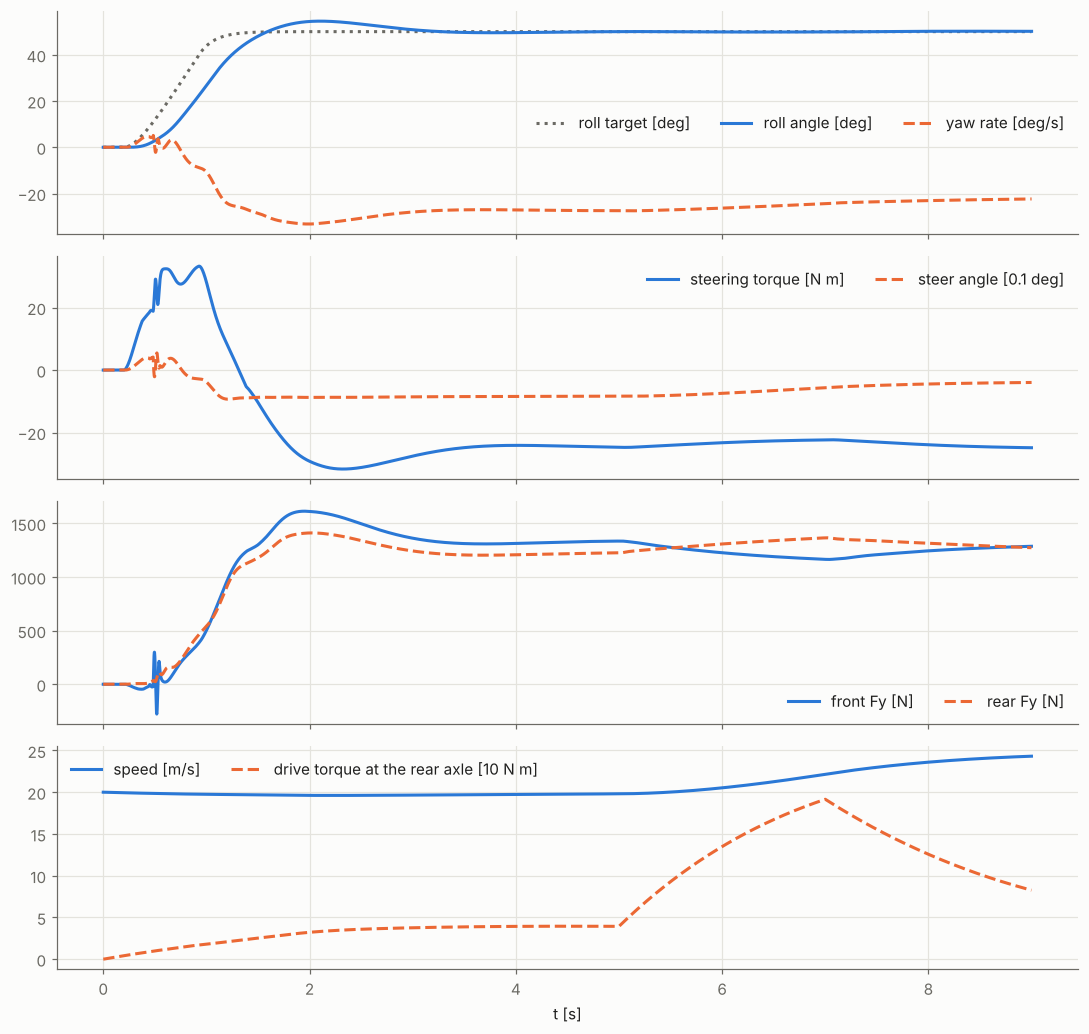

In [3]:
def run_case(system, x0, T, controller, log, **kw):
    t0 = time.perf_counter()
    t, X, L = simulate(system, x0, int(T * FS), controller, log=log, **kw)
    print(f"   {T:.0f} s simulated in {time.perf_counter() - t0:.0f} s")
    return t, X, L

x0 = plant.steady_state(20.0, 0.0)["x"]
roll_c, speed_c = RollController(), SpeedController()
def controller(i, t, k, st, x):
    v_ref = 20.0 + 4.0 * np.clip((t - 5.0) / 2.0, 0, 1)
    return {"Tsteer": roll_c.update(rad(50) if t >= 0.2 else 0.0, k), "Trwy": speed_c.update(v_ref, k)}
def log(i, t, k, st, x, c):
    return dict(v=forward_speed(k), Ts=c["Tsteer"], Tr=c["Trwy"], ref=roll_c.ref, Fyf=st["front"]["Fy"], Fyr=st["rear"]["Fy"])
t, X, L = run_case(plant, x0, 9.0, controller, log)
tl = t[:-1]
fig, ax = plt.subplots(4, 1, figsize=(10, 9.5), sharex=True)
ax[0].plot(tl, deg(L["ref"]), ":", color="#6b6a64", label="roll target [deg]"); ax[0].plot(t, deg(X[:, 8]), color=C[0], label="roll angle [deg]")
ax[0].plot(t, deg(X[:, 20]), "--", color=C[1], label="yaw rate [deg/s]"); ax[0].legend(ncol=3)
ax[1].plot(tl, L["Ts"], color=C[0], label="steering torque [N m]"); ax[1].plot(t, 10 * deg(X[:, 10]), "--", color=C[1], label="steer angle [0.1 deg]"); ax[1].legend(ncol=2)
ax[2].plot(tl, L["Fyf"], color=C[0], label="front Fy [N]"); ax[2].plot(tl, L["Fyr"], "--", color=C[1], label="rear Fy [N]"); ax[2].legend(ncol=2)
ax[3].plot(tl, L["v"], color=C[0], label="speed [m/s]"); ax[3].plot(tl, -L["Tr"] / 10, "--", color=C[1], label="drive torque at the rear axle [10 N m]"); ax[3].legend(ncol=2); ax[3].set_xlabel("t [s]")
plt.tight_layout()
i4 = int(4.8 * FS)
print(f"at t = 4.8 s: roll {deg(X[i4, 8]):.1f}°, steer {deg(X[i4, 10]):.2f}°, yaw rate {X[i4, 20]:.3f} rad/s, steering torque {L['Ts'][i4]:.1f} N m"
      f"   (thesis: ≈ −0.8°, −0.457 rad/s, ≈ −7 N m)")
print(f"roll overshoot {deg(X[:, 8].max()) - 50:.1f}°; counter-steer peak {deg(X[:int(1.5*FS), 10].max()):+.2f}°; end of run: speed {L['v'][-1]:.2f} m/s, roll {deg(X[-1, 8]):.1f}°")

The response has the features of Fig. 7.11 – counter-steer to the left, briefly negative front side force, steer angle settling near −0.8° – and the speed loop then
accelerates the bike in the corner while the roll loop holds 50° (the yaw rate drops as speed rises).

## 4.7 Engine torque and Table 6.1
Wide-open and closed-throttle torque curves (Fig. 4.20) and the typical throttle characteristic (Fig. 4.21) were read off the figures; the map of Fig. 4.22 is
closed-throttle torque plus the throttle share of the span up to wide-open throttle. Rear axle torque = engine torque × primary × gear × final ratio.

overall ratios engine/wheel: [16.89, 12.27, 10.2, 8.92, 7.99, 7.39]


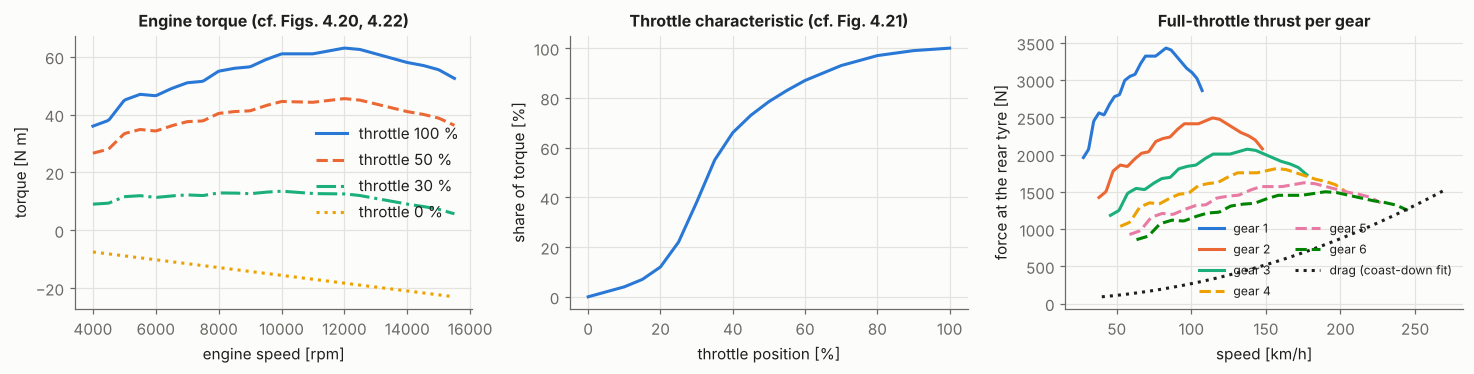

In [4]:
pt = Powertrain()
fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.5))
rpm = np.linspace(4000, 15500, 200)
for i, th in enumerate((1.0, 0.5, 0.3, 0.0)):
    ax[0].plot(rpm, pt.engine_torque(rpm, th), color=C[i], ls=["-", "--", "-.", ":"][i], label=f"throttle {100*th:.0f} %")
ax[0].set_xlabel("engine speed [rpm]"); ax[0].set_ylabel("torque [N m]"); ax[0].legend(); ax[0].set_title("Engine torque (cf. Figs. 4.20, 4.22)")
ax[1].plot(pt.thr, pt.pct); ax[1].set_xlabel("throttle position [%]"); ax[1].set_ylabel("share of torque [%]"); ax[1].set_title("Throttle characteristic (cf. Fig. 4.21)")
r_rear = 0.31
for g in range(1, 7):
    v = rpm * 2 * np.pi / 60 / pt.ratio(g) * r_rear
    ax[2].plot(v * 3.6, pt.engine_torque(rpm, 1.0) * pt.ratio(g) / r_rear, color=C[(g - 1) % len(C)], ls=["-", "--"][(g - 1) // 3 % 2], label=f"gear {g}")
vv = np.linspace(40, 270, 100) / 3.6; d_ = Drag()
ax[2].plot(vv * 3.6, d_.aero(vv) - d_.mechanical(vv), ":", color="#1f1f1e", label="drag (coast-down fit)")
ax[2].set_xlabel("speed [km/h]"); ax[2].set_ylabel("force at the rear tyre [N]"); ax[2].legend(fontsize=8, ncol=2); ax[2].set_title("Full-throttle thrust per gear")
plt.tight_layout()
print("overall ratios engine/wheel:", [round(pt.ratio(g), 2) for g in range(1, 7)])

With the 14/42 final drive of Table 6.1 the thrust curve of sixth gear meets the drag curve of the coast-down fit at about 244 km/h, just below the rev limit in that gear.

## 4.13.1 Traction control (Fig. 4.38)
Rear slip ratio = (wheel speed × tyre contact radius at the current roll angle − forward speed of the rear axle) / axle speed. A roll-dependent target is subtracted,
negative errors are ignored, the rest is multiplied by $K_{tc}$ and subtracted from the engine torque.

Scenario: steady corner at 45° roll and 15 m/s in first gear, throttle opened to 100 % within 0.5 s. The roll controller keeps asking for 45°. Chain force on the
swing-arm (Section 4.5.2) is included.

trim: engine 8452 rpm, throttle 25 %, steering torque -19.5 N m
TC off

   2 s simulated in 2 s
TC on 

   2 s simulated in 6 s
TC off: run ends at t = 0.81 s, max slip ratio 1.831, max rear slip angle 9.0°, max torque reduction 0.0 N m, final speed 1.9 m/s
TC on : run ends at t = 2.00 s, max slip ratio 0.084, max rear slip angle 0.9°, max torque reduction 23.1 N m, final speed 25.1 m/s


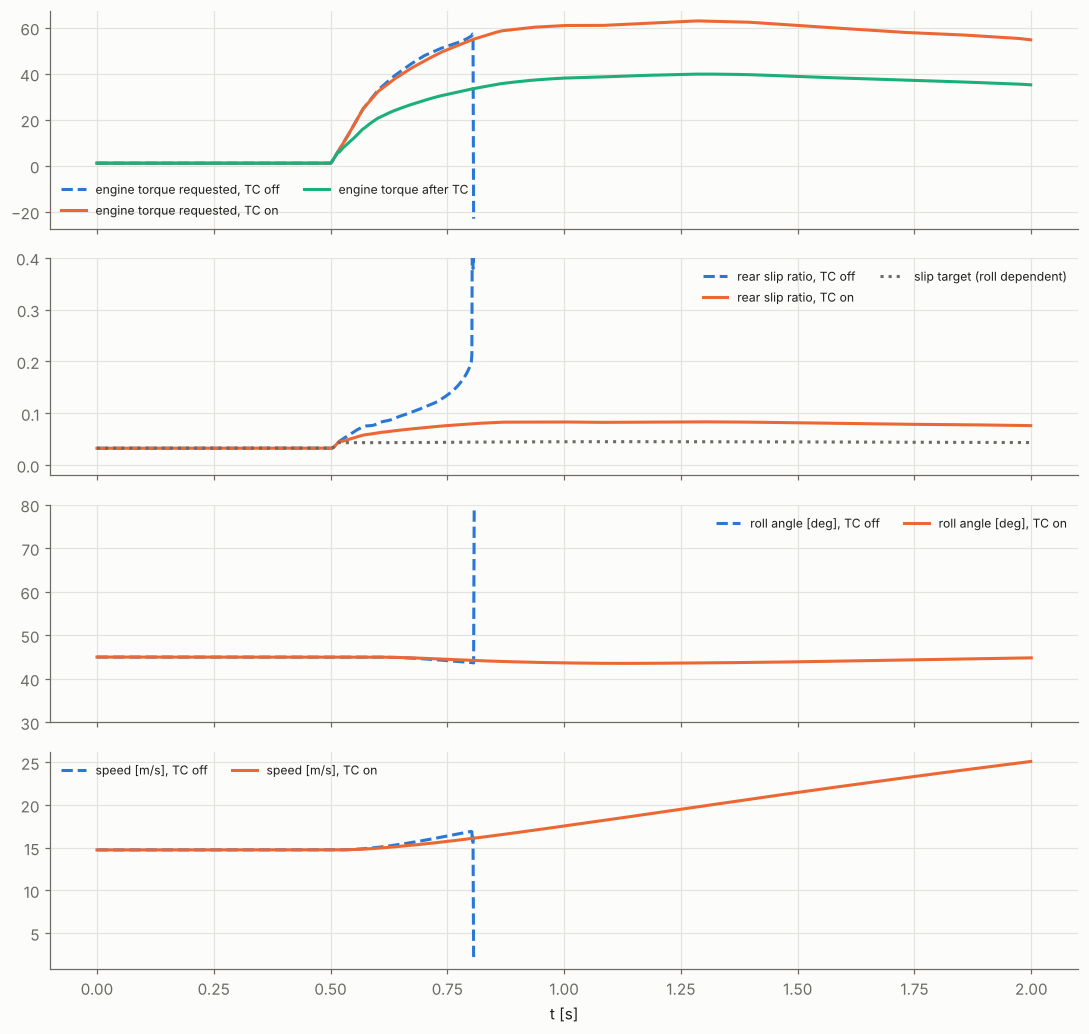

In [5]:
plant_chain = BikeSystem(bike, F, tyres, drag=Drag(), chain=Chain(p.Ra, r_front=0.0357), c_steer=C_STEER)
V0, roll0, gear = 15.0, rad(45), 1
trim = plant_chain.steady_state(V0, roll0)
thr0 = pt.throttle_for(-trim["Trwy"] / pt.ratio(gear), pt.engine_rpm(trim["x"][16], gear))
print(f"trim: engine {pt.engine_rpm(trim['x'][16], gear):.0f} rpm, throttle {100*thr0:.0f} %, steering torque {trim['Tsteer']:.1f} N m")
tc_runs = {}
for enabled in (False, True):
    rc = RollController(); rc.shaper.r = rc.shaper.y = roll0; rc.pid.I = trim["Tsteer"]
    tc = TractionControl(enabled=enabled)
    def controller(i, t, k, st, x):
        thr = thr0 + np.clip((t - 0.5) / 0.5, 0, 1) * (1 - thr0)
        Te = pt.engine_torque(pt.engine_rpm(x[16], gear), thr)
        Te_out = tc.update(k, Te)
        return {"Tsteer": rc.update(roll0, k), "Trwy": pt.axle_torque(Te_out, gear), "_thr": thr, "_Te": Te, "_Tout": Te_out}
    def ctl_clean(i, t, k, st, x):
        c = controller(i, t, k, st, x); ctl_clean.last = c
        return {n: v for n, v in c.items() if not n.startswith("_")}
    def log(i, t, k, st, x, c):
        e = ctl_clean.last
        return dict(slip=tc.slip, err=tc.error, red=tc.reduction, thr=e["_thr"], Te=e["_Te"], Tout=e["_Tout"], v=forward_speed(k), alpha_r=deg(np.arctan(st["rear"]["alpha"])))
    print("TC", "on " if enabled else "off", end=""); tc_runs[enabled] = run_case(plant_chain, trim["x"], 2.0, ctl_clean, log, stop=lambda x: abs(x[8]) > rad(75))
fig, ax = plt.subplots(4, 1, figsize=(10, 9.5), sharex=True)
for i, (enabled, lab) in enumerate(((False, "TC off"), (True, "TC on"))):
    t, X, L = tc_runs[enabled]; tl = t[:-1]; ls = ["--", "-"][i]
    ax[0].plot(tl, L["Te"], ls, color=C[i], label=f"engine torque requested, {lab}"); 
    if enabled: ax[0].plot(tl, L["Tout"], "-", color=C[2], label="engine torque after TC")
    ax[1].plot(tl, L["slip"], ls, color=C[i], label=f"rear slip ratio, {lab}")
    ax[2].plot(t, deg(X[:, 8]), ls, color=C[i], label=f"roll angle [deg], {lab}")
    ax[3].plot(tl, L["v"], ls, color=C[i], label=f"speed [m/s], {lab}")
ax[1].plot(tc_runs[True][0][:-1], tc_runs[True][2]["slip"] - tc_runs[True][2]["err"], ":", color="#6b6a64", label="slip target (roll dependent)")
ax[1].set_ylim(-0.02, 0.4); ax[2].set_ylim(30, 80)
for a in ax: a.legend(ncol=2, fontsize=8)
ax[3].set_xlabel("t [s]"); plt.tight_layout()
for enabled in (False, True):
    t, X, L = tc_runs[enabled]; ok = np.isfinite(X[:, 8])
    print(f"TC {'on ' if enabled else 'off'}: run ends at t = {t[ok][-1]:.2f} s, max slip ratio {np.nanmax(L['slip']):.3f}, max rear slip angle {np.nanmax(abs(L['alpha_r'])):.1f}°, "
          f"max torque reduction {np.nanmax(L['red']):.1f} N m, final speed {L['v'][np.isfinite(L['v'])][-1]:.1f} m/s")

Without TC the rear tyre spins up, the side force collapses and the model "crashes" within a fraction of a second. With TC the slip ratio stays a little above the
target (the strategy is proportional, so some error remains) and the bike accelerates out of the corner. The run stops at 2 s, shortly before first gear reaches the rev limit.

## 4.13.2 Anti-lock braking (Fig. 4.39)
Same slip calculation, only negative slip counts. The brake torque is multiplied by $1+K_{abs}(\text{slip}-\text{target})$. The thesis' example: slip −0.1, target −0.05,
$K_{abs}$ = 2 → factor 0.9 (verified in `tests/`). Once active, the strategy works against a stricter target until the slip has recovered, and the front strategy is disabled
near full fork extension (wheelie).

Scenario: straight line at 40 m/s on a low-grip surface ($\mu_x$ = 0.8 instead of 1.44), front brake torque ramped to 700 N m.
The brake is a friction element (`brake_torque`): it opposes the rotation and cannot drive a locked wheel backwards.

ABS off

   3 s simulated in 8 s
Kabs = 2

   3 s simulated in 8 s
Kabs = 10

   3 s simulated in 8 s
ABS off   : min slip -0.994, slip at the end -0.992, mean deceleration after the ramp 4.35 m/s²
Kabs = 2  : min slip -0.297, slip at the end -0.292, mean deceleration after the ramp 4.89 m/s²
Kabs = 10 : min slip -0.069, slip at the end -0.068, mean deceleration after the ramp 5.40 m/s²


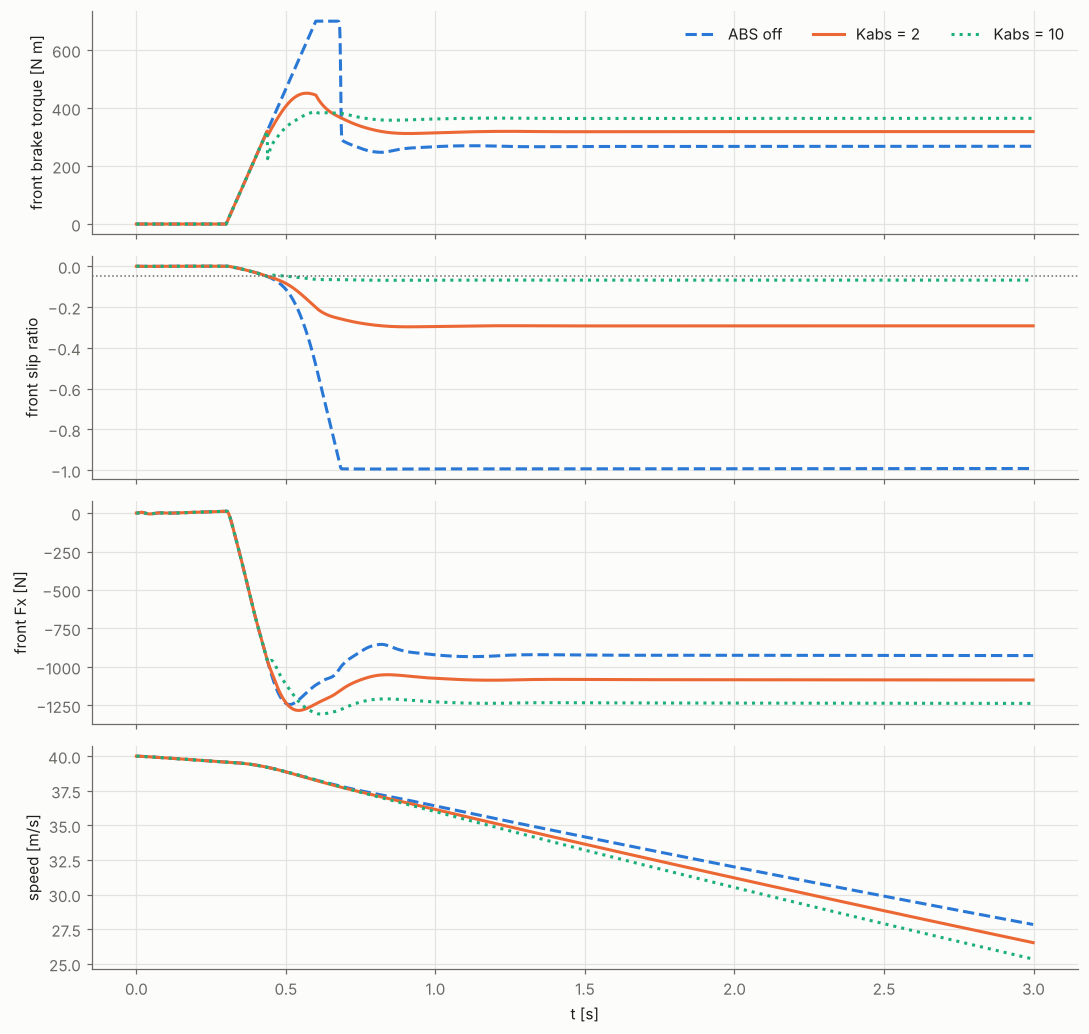

In [6]:
wet = TyreSet(MagicFormula(front_tyre(True, True).copy(pDx1=0.8, pDy1=0.9)), MagicFormula(rear_tyre().copy(pDx1=0.8, pDy1=0.9)))
plant_wet = BikeSystem(bike, F, wet, drag=Drag(), c_steer=C_STEER)
x0w = plant_wet.steady_state(40.0, 0.0)["x"]
abs_runs = {}
for lab, strat in [("ABS off", ABS(enabled=False)), ("Kabs = 2", ABS(Kabs=2.0)), ("Kabs = 10", ABS(Kabs=10.0))]:
    rc = RollController()
    def controller(i, t, k, st, x):
        Tb = 700.0 * np.clip((t - 0.3) / 0.3, 0, 1)
        return {"Tsteer": rc.update(0.0, k), "Tfwy": strat.update(k, brake_torque(Tb, x[15]))}
    def log(i, t, k, st, x, c):
        return dict(slip=strat.slip, factor=strat.factor, T=c["Tfwy"], v=forward_speed(k), Fx=st["front"]["Fx"], active=float(strat.active))
    print(lab, end=""); abs_runs[lab] = run_case(plant_wet, x0w, 3.0, controller, log)
fig, ax = plt.subplots(4, 1, figsize=(10, 9.5), sharex=True)
for i, (lab, (t, X, L)) in enumerate(abs_runs.items()):
    tl = t[:-1]; ls = ["--", "-", ":"][i]
    ax[0].plot(tl, L["T"], ls, color=C[i], label=lab); ax[1].plot(tl, L["slip"], ls, color=C[i], label=lab)
    ax[2].plot(tl, L["Fx"], ls, color=C[i], label=lab); ax[3].plot(tl, L["v"], ls, color=C[i], label=lab)
ax[0].set_ylabel("front brake torque [N m]"); ax[1].set_ylabel("front slip ratio"); ax[2].set_ylabel("front Fx [N]"); ax[3].set_ylabel("speed [m/s]"); ax[3].set_xlabel("t [s]")
ax[1].axhline(-0.05, color="#6b6a64", lw=1, ls=":"); ax[0].legend(ncol=3); plt.tight_layout()
for lab, (t, X, L) in abs_runs.items():
    i0 = int(0.6 * FS)
    print(f"{lab:10s}: min slip {np.nanmin(L['slip']):6.3f}, slip at the end {L['slip'][-1]:6.3f}, mean deceleration after the ramp {(L['v'][i0] - L['v'][-1]) / (t[-2] - t[i0]):.2f} m/s²")

Without ABS the front wheel locks (slip −1) and the deceleration drops to the sliding value. With the thesis' example gain the wheel no longer locks but settles at a
deep slip; a higher gain holds it close to the target and gives the best deceleration. (In a straight line on a flat road the locked front wheel does not make this
model fall, the lateral dynamics are simply not excited.) `ABS(wheel="rear")` works the same way on the rear brake.

## 4.12 The model as an observer (Figs. 4.35–4.37)
When the model is driven by recorded data, the road speed is the open-loop result of wheel torques and drag, so it drifts. The thesis adds a Kalman filter that
corrects the wheel speeds with the recorded ones,

$$s_k=R+C_kP_kC_k^T,\quad K_k=A_kP_kC_k^Ts_k^{-1},\quad \hat x_{k+1}=A_k\hat x_k+B_ku_k+K_k(y_k-C_k\hat x_k),\quad P_{k+1}=A_kP_kA_k^T+Q-K_kC_kP_kA_k^T,$$

and a steering-torque controller that forces the model's body rates to follow the rate gyros (gains $g_1,g_2,g_3$).

Implementation in `run_observer`:
* "$A\hat x+Bu$" is one step of the non-linear model with the recorded axle torques;
* $A_k=I+\Delta t\,A$ with the thesis-form matrix $A$ of notebook 4 (`state_space`), re-scheduled every 0.1 s; the measurement rows of $C$ are those of $u_5$, $u_6$;
  $Q$ acts on the wheel speeds only, so the filter corrects the wheel speeds (and wheel angles) and the tyres pull the vehicle speed along;
* steering: $T=g_1(\omega_1-\hat\omega_1)+g_2(\omega_2-\hat\omega_2)+g_3(\omega_3-\hat\omega_3)+g_0(\gamma-\hat\gamma)$. The last term is **not in Fig. 4.36**: with rate
  feedback alone the slow capsize mode of this model is not stabilised (table at the top: rate gain without angle gain), so the recorded roll angle – output 8 of the
  thesis' $C$ matrix – is used as well.

### Synthetic recording
"Truth": the plant above (with aerodynamic drag) ridden by the two controllers through acceleration, a right and a left corner and braking. Recorded at 800 Hz with
noise: wheel speeds (σ = 0.2 rad/s), rate gyros (σ = 0.01 rad/s), roll angle (σ = 0.5°), and the rear axle torque.

In [7]:
T_rec = 12.0; n = int(T_rec * FS)
x0 = plant.steady_state(25.0, 0.0)["x"]
rc, sc = RollController(), SpeedController()
def rider(i, t, k, st, x):
    v_ref = 25 + 7 * np.clip((t - 1) / 4, 0, 1) - 9 * np.clip((t - 7) / 3, 0, 1)
    roll_ref = rad(40) * (1.5 <= t < 5.5) - rad(35) * (5.5 <= t < 9.0)
    return {"Tsteer": rc.update(roll_ref, k), "Trwy": sc.update(v_ref, k)}
def rec(i, t, k, st, x, c):
    w = body_rates(k); return dict(Trwy=c["Trwy"], w1=w[0], w2=w[1], w3=w[2], v=forward_speed(k))
print("truth:", end=""); t, Xt, Lt = run_case(plant, x0, T_rec, rider, rec)
rng = np.random.default_rng(0); pad = lambda a: np.append(a, a[-1])
data = dict(Trwy=pad(Lt["Trwy"]), Tfwy=np.zeros(n + 1),
            u5=Xt[:, 15] + rng.normal(0, 0.2, n + 1), u6=Xt[:, 16] + rng.normal(0, 0.2, n + 1),
            gyro=np.column_stack([pad(Lt[c]) for c in ("w1", "w2", "w3")]) + rng.normal(0, 0.01, (n + 1, 3)),
            roll=Xt[:, 8] + rng.normal(0, rad(0.5), n + 1))
v_true = pad(Lt["v"])

truth:

   12 s simulated in 31 s


### Observer with a wrong model
The observer model has **no aerodynamic drag** and applies the recorded axle torque with a **10 % calibration error** – the kind of error the thesis describes
("very difficult to determine exactly all of the parameters affecting the speed").

no Kalman filter: 32 s


Kalman filter: 35 s


Kalman filter, rate gyros only (g0 = 0): 35 s
                                           rms wheel-speed err   max speed err   rms roll err   position err at 12 s   heading err
no Kalman filter                                19.15 rad/s         9.04 m/s        5.49°           57.5 m           -3.8°
Kalman filter                                    0.32 rad/s         0.70 m/s        4.51°           10.3 m           -1.8°
Kalman filter, rate gyros only (g0 = 0)          0.31 rad/s         1.94 m/s       16.90°           12.9 m          -22.2°


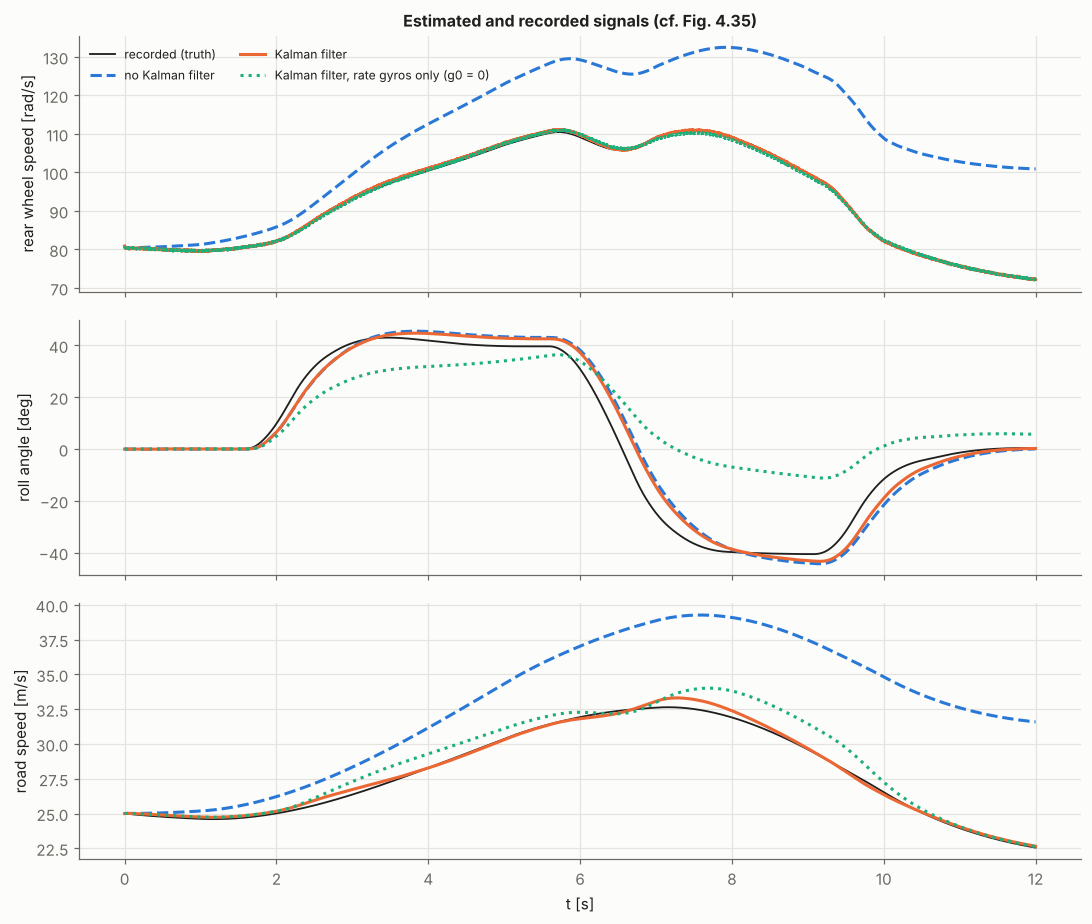

In [8]:
observer_model = BikeSystem(bike, F, tyres, drag=None, c_steer=C_STEER)
olog = lambda i, t, k, st, x, c: dict(v=forward_speed(k), Ts=c["Tsteer"])
obs = {}
for name, kw in [("no Kalman filter", dict(kalman=False)),
                 ("Kalman filter", dict(kalman=True)),
                 ("Kalman filter, rate gyros only (g0 = 0)", dict(kalman=True, steer=GyroSteer(g0=0.0, g1=60.0, g2=-60.0)))]:
    t0 = time.perf_counter()
    obs[name] = run_observer(observer_model, x0, data, torque_gain=1.1, log=olog, **kw)
    print(f"{name}: {time.perf_counter() - t0:.0f} s")

fig, ax = plt.subplots(3, 1, figsize=(10, 8.5), sharex=True)
ax[0].plot(t, -Xt[:, 16], color="#1f1f1e", lw=1.2, label="recorded (truth)"); ax[1].plot(t, deg(Xt[:, 8]), color="#1f1f1e", lw=1.2, label="recorded (truth)")
ax[2].plot(t, v_true, color="#1f1f1e", lw=1.2, label="truth")
for i, (name, (to, Xo, Lo)) in enumerate(obs.items()):
    ls = ["--", "-", ":"][i]
    ax[0].plot(to, -Xo[:, 16], ls, color=C[i], label=name); ax[1].plot(to, deg(Xo[:, 8]), ls, color=C[i], label=name)
    ax[2].plot(to[:-1], Lo["v"], ls, color=C[i], label=name)
ax[0].set_ylabel("rear wheel speed [rad/s]"); ax[1].set_ylabel("roll angle [deg]"); ax[2].set_ylabel("road speed [m/s]"); ax[2].set_xlabel("t [s]")
ax[0].legend(fontsize=8, ncol=2); ax[0].set_title("Estimated and recorded signals (cf. Fig. 4.35)"); plt.tight_layout()

print(f"{'':42s} rms wheel-speed err   max speed err   rms roll err   position err at 12 s   heading err")
for name, (to, Xo, Lo) in obs.items():
    e = Xo - Xt; ok = np.isfinite(Xo[:, 8]); j = np.where(ok)[0][-1]
    print(f"{name:42s} {np.sqrt(np.nanmean(e[:, 16]**2)):10.2f} rad/s {np.nanmax(abs(Lo['v'] - Lt['v'])):12.2f} m/s {deg(np.sqrt(np.nanmean(e[:, 8]**2))):11.2f}° "
          f"{np.hypot(e[j, 6], e[j, 7]):14.1f} m {deg(e[j, 9]):14.1f}°" + ("" if ok.all() else f"   (run ended at {to[j]:.1f} s)"))

### Path (cf. Fig. 4.37)
Position and heading are pure integrals, so they drift in every case – as the thesis shows against GPS.

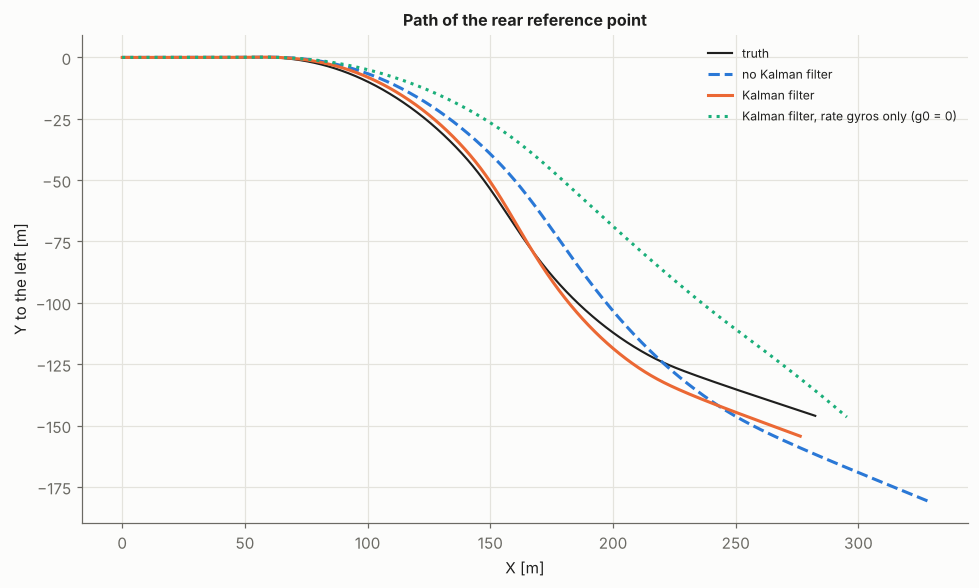

In [9]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(Xt[:, 6], -Xt[:, 7], color="#1f1f1e", lw=1.4, label="truth")
for i, (name, (to, Xo, Lo)) in enumerate(obs.items()):
    ax.plot(Xo[:, 6], -Xo[:, 7], ["--", "-", ":"][i], color=C[i], label=name)
ax.set_aspect("equal"); ax.set_xlabel("X [m]"); ax.set_ylabel("Y to the left [m]"); ax.legend(fontsize=8); ax.set_title("Path of the rear reference point")
plt.tight_layout()

## Remarks
* The Kalman gain acts on the wheel-speed states only. With the Hammerstein $A$ matrix that is all it can do: the tyre forces that couple wheel speed and road speed
  are inputs, not part of $A$ (Section 4.5).
* Gains, targets and covariances here are for the estimated parameter set; they are not thesis values and need re-tuning with real data.
* Not covered: brake-pressure → torque calibration (Section 6.6.10, a proportional constant found by matching decelerations), gear-position reconstruction,
  and chapters 6–8 (sensing, validation against track data, application examples).